In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.decomposition import KernelPCA
import matplotlib.pyplot as plt

# Load in dataset
df = pd.read_csv("spotify.csv")

# drop rows of missing key identifiers
df = df.dropna(subset = ["track_name", "artists"])

#handle missing values
df = df.fillna(df.mean(numeric_only = True))

#convert bool to numeric
df["explicit"] = df["explicit"].astype(int)

# Drop non-useful 
drop_cols = [
    "track_id",
    "track_name",
    "artists",
    "album_name",
    "track_genre"
]

df_clean = df.drop(columns=drop_cols)

#select features
features = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "key",
    "loudness",
    "mode",
    "speechiness",
    "acousticness",
    "instrumentalness",
    "liveness",
    "valence",
    "tempo",
    "time_signature",
    "explicit"
]

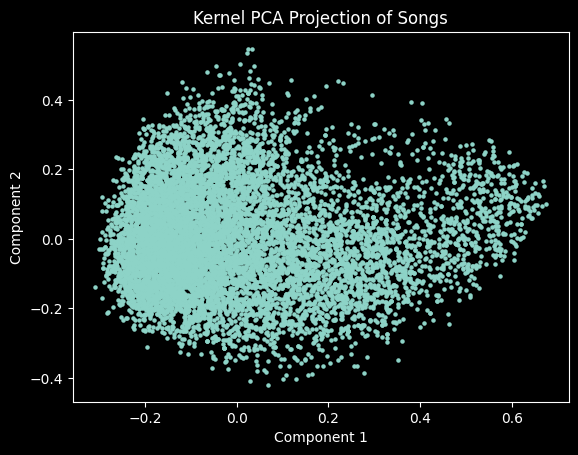

In [33]:

X = df_clean[features]

#handle outliers
X = X.clip(lower=X.quantile(0.01),
           upper=X.quantile(0.99),
           axis=1)

#Normalize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# subset for kernal PCA
sample_size = 10000
df_sample = df.sample(sample_size, random_state=42)
df_sample = df_sample.copy()

X_sample = X_scaled[df_sample.index]

# apply kernel PCA
kpca = KernelPCA(
    n_components=2,
    kernel="rbf",
    gamma=0.01,
    random_state=42
)

X_kpca = kpca.fit_transform(X_sample)

# add back to df
df_sample["kpca_1"] = X_kpca[:, 0]
df_sample["kpca_2"] = X_kpca[:, 1]


plt.scatter(df_sample["kpca_1"], df_sample["kpca_2"], s=5)
plt.title("Kernel PCA Projection of Songs")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

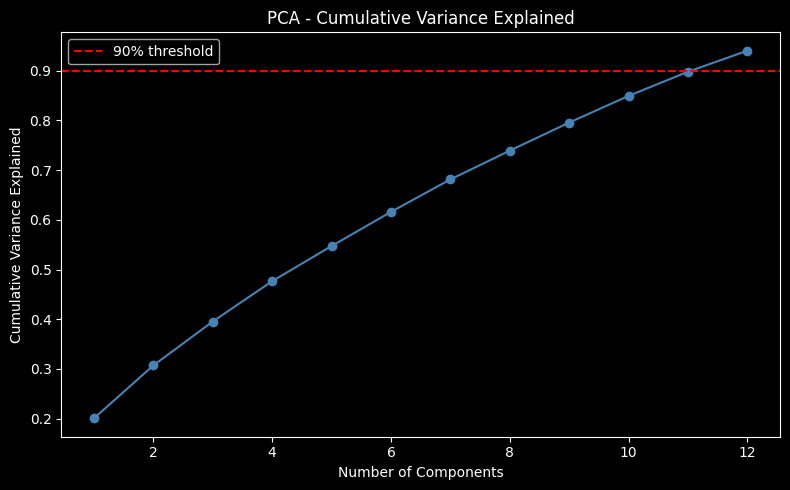

In [34]:
from sklearn.decomposition import PCA

# Run regular PCA on the full dataset (all 114,000 songs)
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Reduced from {X_scaled.shape[1]} features to {X_pca.shape[1]} components")
print(f"Variance explained: {sum(pca.explained_variance_ratio_):.3f}")

# Variance explained plot
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', color='steelblue')
plt.axhline(y=0.90, color='red', linestyle='--', label='90% threshold')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Variance Explained")
plt.title("PCA - Cumulative Variance Explained")
plt.legend()
plt.tight_layout()
plt.show()

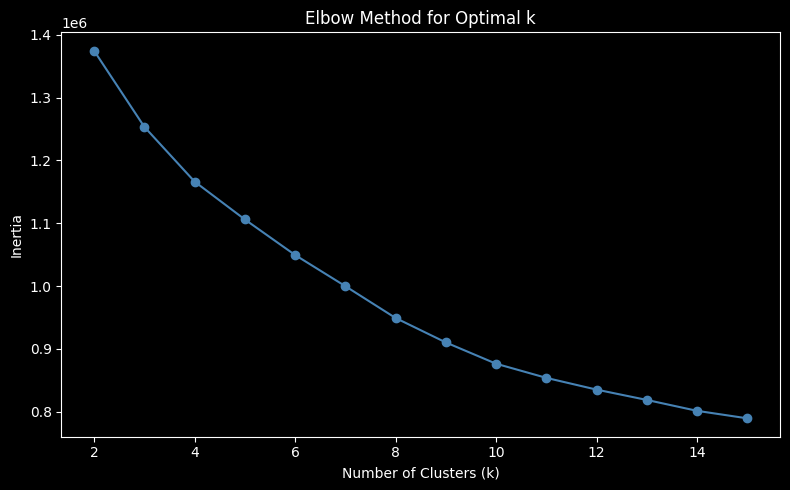

In [35]:
from sklearn.cluster import KMeans

# Elbow method to find optimal k
inertia = []
k_values = range(2, 16)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_pca)
    inertia.append(km.inertia_)

# Elbow plot
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, marker='o', color='steelblue')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.tight_layout()
plt.show()

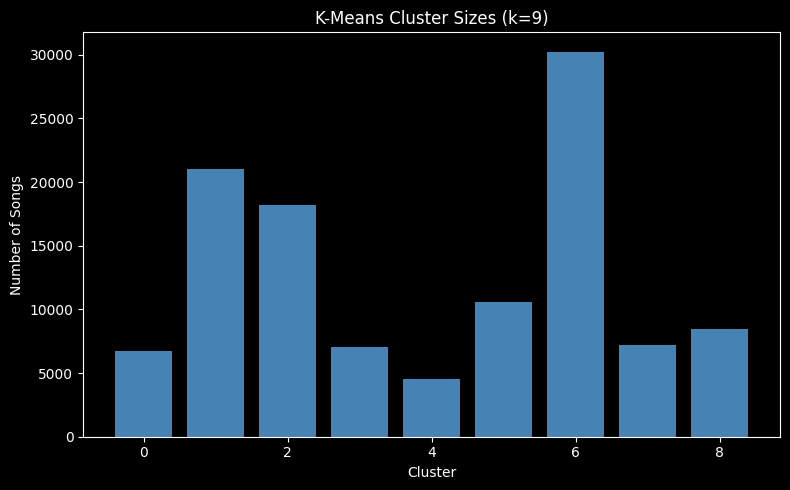

In [36]:
BEST_K = 9

kmeans = KMeans(n_clusters=BEST_K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

# Save cluster labels back to the original dataframe
df["kmeans_cluster"] = kmeans_labels

print("K-Means done. Cluster distribution:")
print(df["kmeans_cluster"].value_counts().sort_index())

# Plot bar chart of cluster sizes for K-Means
plt.figure(figsize=(8, 5))
cluster_counts = df["kmeans_cluster"].value_counts().sort_index()
plt.bar(cluster_counts.index, cluster_counts.values, color="steelblue")
plt.xlabel("Cluster")
plt.ylabel("Number of Songs")
plt.title("K-Means Cluster Sizes (k=9)")
plt.tight_layout()
plt.show()

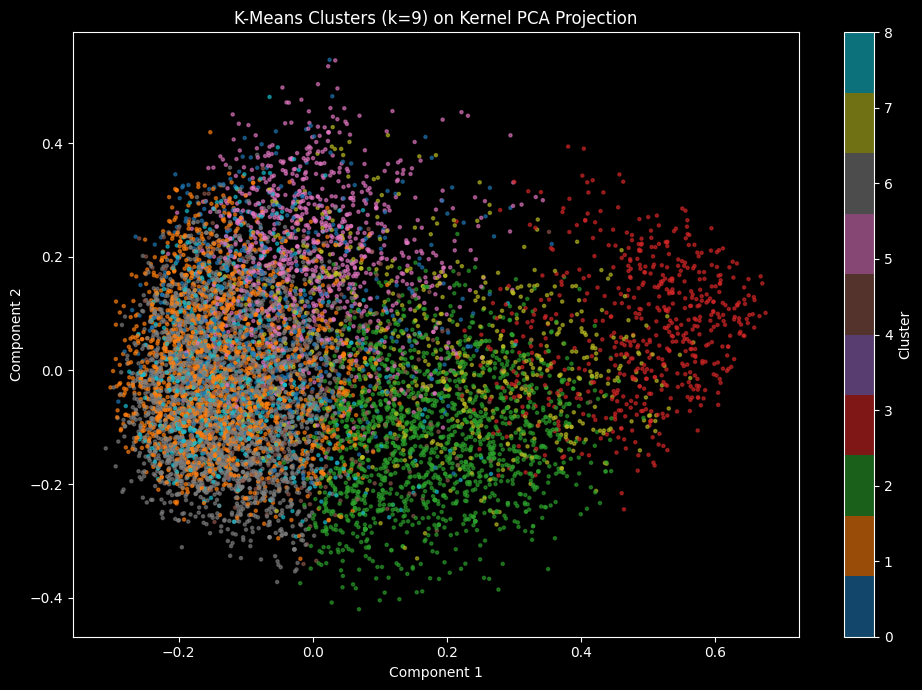

In [37]:
# Use the 10k sample and map kmeans labels back to the sample
sample_kmeans_labels = kmeans_labels[df_sample.index]

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    df_sample["kpca_1"],
    df_sample["kpca_2"],
    c=sample_kmeans_labels,
    cmap="tab10",
    s=5,
    alpha=0.6
)
plt.colorbar(scatter, label="Cluster")
plt.title("K-Means Clusters (k=9) on Kernel PCA Projection")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.tight_layout()
plt.show()

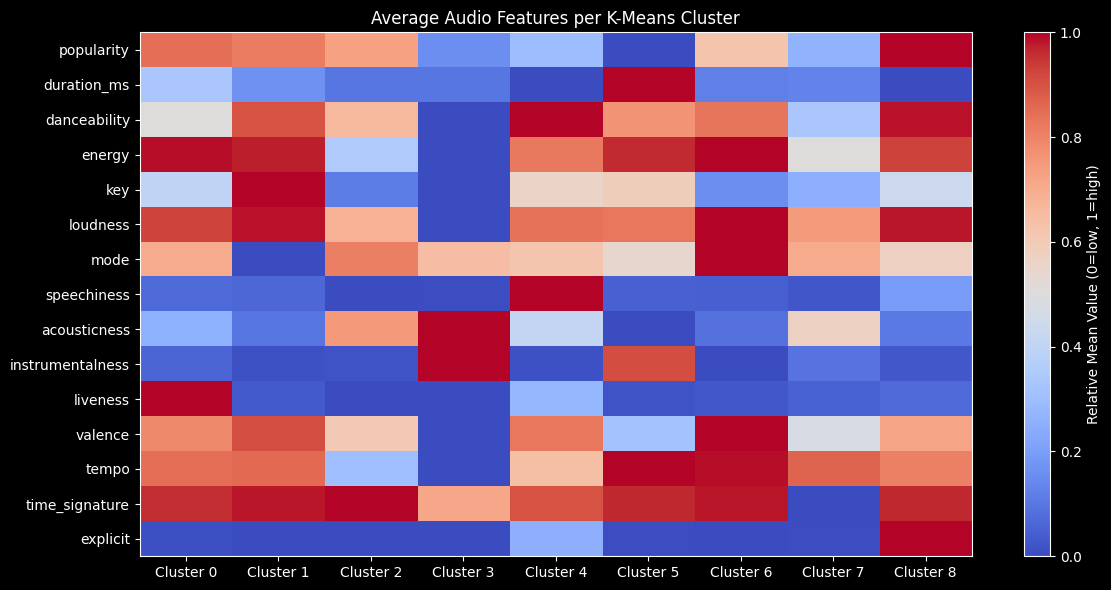

In [38]:
cluster_profiles = df.groupby("kmeans_cluster")[features].mean()

# Normalize across each feature (column), not each cluster (row)
cluster_profiles_normalized = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min())

# Heatmap of Average Audio Features per K-Means Cluster
plt.figure(figsize=(12, 6))
plt.imshow(cluster_profiles_normalized.T, aspect="auto", cmap="coolwarm")
plt.colorbar(label="Relative Mean Value (0=low, 1=high)")
plt.xticks(range(9), [f"Cluster {i}" for i in range(9)])
plt.yticks(range(len(features)), features)
plt.title("Average Audio Features per K-Means Cluster")
plt.tight_layout()
plt.show()

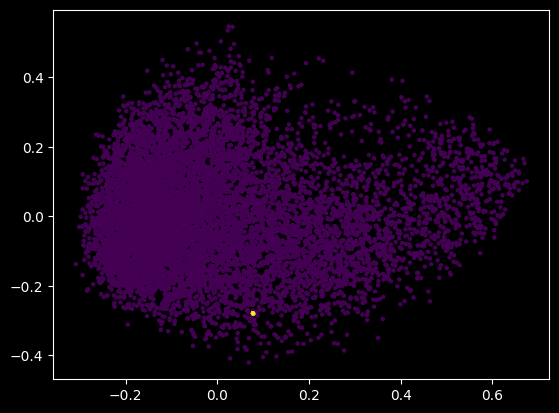

In [39]:
from sklearn.cluster import DBSCAN

coords = KernelPCA(n_components=2, kernel="rbf", gamma=0.01).fit_transform(X_sample)

labels = DBSCAN(eps=0.8, min_samples=10).fit_predict(X_sample)

plt.scatter(coords[:, 0], coords[:, 1], c=labels, s=5, cmap="viridis")
plt.show()

DBSCAN looks for tight clumps of points with empty space between them.
Our data is more like a continuous cloud of songs with gradual differences.
So everything stays connected, and DBSCAN merges it into one big group
Even when you shrink eps, the space is still too uniformly filled, so it doesn't “break apart” into meaningful clusters.


In [40]:
# Runtime takes about 8 minutes
dbscan = DBSCAN(eps=2.0, min_samples=10)
dbscan_labels = dbscan.fit_predict(X_pca)

df["dbscan_cluster"] = dbscan_labels

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = list(dbscan_labels).count(-1)

print(f"DBSCAN clusters found: {n_clusters}")
print(f"Noise points: {n_noise}")
print(f"\nCluster distribution:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters found: 25
Noise points: 2430

Cluster distribution:
-1      2430
 0     33322
 1     59180
 2      6229
 3      4929
 4      2687
 5       660
 6       273
 7      3523
 8        42
 9        12
 10       24
 11      118
 12      105
 13       63
 14      146
 15       92
 16       30
 17       25
 18       29
 19       17
 20        8
 21       10
 22       11
 23       13
 24       21
Name: count, dtype: int64


In [42]:
from sklearn.metrics import silhouette_score, f1_score
from scipy.optimize import linear_sum_assignment
sil_score = silhouette_score(X_pca, kmeans_labels)
print("Silhouette Score (K-Means):", sil_score)

Silhouette Score (K-Means): 0.13318595588160773


In [44]:
if "track_genre" in df.columns:

    true_labels = df["track_genre"].astype("category").cat.codes

    # ---- Step 1: match cluster IDs to genre labels ----
    # build confusion matrix between clusters and genres
    contingency = pd.crosstab(kmeans_labels, true_labels).values

    # Hungarian algorithm to best match clusters -> genres
    row_ind, col_ind = linear_sum_assignment(-contingency)

    # create mapping from cluster -> best genre label
    cluster_to_genre = {row: col for row, col in zip(row_ind, col_ind)}

    # remap predicted clusters
    mapped_clusters = np.array([cluster_to_genre[c] for c in kmeans_labels])

    # compute F1 score
    f1 = f1_score(true_labels, mapped_clusters, average="weighted")

    print("Weighted F1-score (cluster vs genre alignment):", f1)

else:
    print("track_genre not found: skipping F1-score calculation")

KeyError: 'artist'